# 第 9 章配套 Notebook：非线性运算为什么难转换：max、乘法、GELU、Softmax 与 LayerNorm 反例与突围

[![Open In Colab (main)](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/main/notion/notebooks/ch09_nonlinear_operators.ipynb) （PR 审查期分支链接：[点此在 Colab 打开 gemini/deep-03 版](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/gemini/deep-03/notion/notebooks/ch09_nonlinear_operators.ipynb)）

> **运行环境**：仅需 Python ≥ 3.10、`numpy`、`matplotlib`，不需要 GPU，也不依赖 PyTorch 等深度学习框架。所有公式推导、手算例与反例均直接打印中间结果并与第 9 章正文逐位核对一致。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

# 配置中文与负号显示（Windows / Linux / macOS / Colab 通用回退）
matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'Arial Unicode MS', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False
np.set_printoptions(precision=6, suppress=True)
print("NumPy version:", np.__version__)


NumPy version: 2.5.5


## 1. 取最大值（`max`）为什么不能逐步做脉冲转换？（例 9.1 & 例 9.2）

1. **例 9.1（相位错开双反例）**：`s1 = [1, 0, 1, 0]`（发放率 `0.5`）与 `s2 = [0, 1, 0, 1]`（发放率 `0.5`），逐步取最大得 `[1, 1, 1, 1]`，发放率暴涨为 `1.0`（高估一倍！）；
2. **验证 Li & Zeng（IJCAI 2022）式 (11)**：$\max(\mathbf{r}) \le r_{\mathrm{step\text{-}max}} \le \min(1, \sum_j r_j)$；
3. **例 9.2（最大化偏置，Thrun & Schwartz 1993 / van Hasselt 2010）**：即使 $k$ 个候选输入完全打平、各自加上零均值独立均匀误差 $\eta_j \sim \mathcal{U}[-\epsilon, \epsilon]$，取最大值也会产生系统性正偏置 $\mathbb{E}[\max_j \eta_j] = \frac{k-1}{k+1}\epsilon$（ViG 默认 $k=9$ 时高达 $0.80\epsilon$，$k=20$ 时达 $0.905\epsilon$！）。

In [2]:
# 例 9.1: 逐步取 max 的核心反例
s1 = np.array([1, 0, 1, 0], dtype=float)
s2 = np.array([0, 1, 0, 1], dtype=float)
r1, r2 = s1.mean(), s2.mean()
true_max = max(r1, r2)
step_max_seq = np.maximum(s1, s2)
step_max_rate = step_max_seq.mean()

print("=== 例 9.1: 逐步取 max 反例 ===")
print(f"s1 = {s1.astype(int).tolist()} (r1 = {r1:.2f})")
print(f"s2 = {s2.astype(int).tolist()} (r2 = {r2:.2f})")
print(f"真实 max(r1, r2)          = {true_max:.2f}")
print(f"逐步 max(s1[t], s2[t])    = {step_max_seq.astype(int).tolist()} -> 发放率 = {step_max_rate:.2f} (高估 {step_max_rate - true_max:+.2f}!)")
assert np.isclose(true_max, 0.5)
assert np.isclose(step_max_rate, 1.0)
assert true_max <= step_max_rate <= min(1.0, r1 + r2)

# 例 9.2: 最大化偏置 E[max_j eta_j] = (k-1)/(k+1) * eps (蒙特卡洛 100,000 次验证)
rng = np.random.default_rng(42)
eps_noise = 0.10
ks = [2, 4, 9, 16, 20]
print("\n=== 例 9.2: 均匀零均值噪声 U[-eps, eps] 的最大化正偏置 (eps = 0.10) ===")
sim_biases = []
th_biases = []
for k in ks:
    eta = rng.uniform(-eps_noise, eps_noise, size=(100_000, k))
    emp = float(np.mean(np.max(eta, axis=1)))
    theo = (k - 1) / (k + 1) * eps_noise
    sim_biases.append(emp)
    th_biases.append(theo)
    print(f"  k = {k:2d}: 理论 (k-1)/(k+1)*eps = {theo:.5f} ({(k-1)/(k+1):.3f}*eps) | 仿真 = {emp:.5f}")
    assert abs(emp - theo) < 1e-3


=== 例 9.1: 逐步取 max 反例 ===
s1 = [1, 0, 1, 0] (r1 = 0.50)
s2 = [0, 1, 0, 1] (r2 = 0.50)
真实 max(r1, r2)          = 0.50
逐步 max(s1[t], s2[t])    = [1, 1, 1, 1] -> 发放率 = 1.00 (高估 +0.50!)

=== 例 9.2: 均匀零均值噪声 U[-eps, eps] 的最大化正偏置 (eps = 0.10) ===
  k =  2: 理论 (k-1)/(k+1)*eps = 0.03333 (0.333*eps) | 仿真 = 0.03327
  k =  4: 理论 (k-1)/(k+1)*eps = 0.06000 (0.600*eps) | 仿真 = 0.05997
  k =  9: 理论 (k-1)/(k+1)*eps = 0.08000 (0.800*eps) | 仿真 = 0.08004
  k = 16: 理论 (k-1)/(k+1)*eps = 0.08824 (0.882*eps) | 仿真 = 0.08822
  k = 20: 理论 (k-1)/(k+1)*eps = 0.09048 (0.905*eps) | 仿真 = 0.09049


## 2. Bu 等（CVPR 2025）“把 MaxPool 挪到脉冲神经元之前”的精确条件，以及为什么 ViG 用不上（例 9.3）

1. 验证 **Bu 等 Theorem 2（式 16 / 式 S19）**：$\max_j \mathrm{ReLU}(z_j) = \mathrm{ReLU}(\max_j z_j)$ 不仅在原文所写的 $\max_j z_j > 0$ 时成立，在 $\max_j z_j \le 0$ 时两边也同为 `0`（因为 ReLU 单调不减）；
2. 验证本课程补全的 **SNN 时域隐含条件**（`推导（非论文原文）`）：当膜前电流 $z_j[t]$ 随时间波动、胜者下标 $j^*$ 来回切换时，即便把 `MaxPool` 搬到 IF 神经元之前，仍有 $\frac{1}{T}\sum_t \max_j z_j[t] > \max_j \bar{z}_j$；只有当电流恒定或胜者下标跨时间不变时才无损；
3. **例 9.3（ViG 为何用不上）**：ViG 在 `MRConv` 里对可正可负的相对差 $\tilde{\mathbf{x}}_j - \tilde{\mathbf{x}}_i$ 取最大后直接拼接 $[\tilde{\mathbf{x}}_i \Vert \mathbf{m}_i]$ 送进线性层 $W_{\mathrm{update}}$，**后面没有紧跟 ReLU 可以交换**；若强行套用 ReLU/单极性 IF 会抹掉负值 $\mathbf{m}_i = -0.2$，导致线性层输出错误！

In [3]:
def relu(x):
    return np.maximum(0.0, x)

# 1) 验证 ReLU 与 max 交换律对任意实数向量（含全负）均成立
for z in [np.array([-1.2, 0.5, 2.3]), np.array([-2.0, -0.5, -1.3]), np.array([0.0, -0.1])]:
    lhs = np.max(relu(z))
    rhs = relu(np.max(z))
    assert np.isclose(lhs, rhs)
print("验证通过：max(ReLU(z)) == ReLU(max(z)) 对正、负、零任意实数向量恒成立。")

# 2) 验证 SNN 时域条件（推导，非论文原文）: 胜者跨时间切换时，即使前置 MaxPool 也会高估！
z1_t = np.array([2.0, 0.0, 2.0, 0.0])  # mean = 1.0
z2_t = np.array([0.0, 2.0, 0.0, 2.0])  # mean = 1.0
true_pre_max = max(z1_t.mean(), z2_t.mean())  # 1.0
inst_max_mean = np.maximum(z1_t, z2_t).mean()  # 2.0!
print("\n=== SNN 时域条件反例（前置 MaxPool 遇到波动电流） ===")
print(f"z1[1..4] = {z1_t.tolist()} (均值 {z1_t.mean():.2f})")
print(f"z2[1..4] = {z2_t.tolist()} (均值 {z2_t.mean():.2f})")
print(f"理想 max(mean z1, mean z2) = {true_pre_max:.2f}, 但逐步前置 max 的均值 = {inst_max_mean:.2f} (高估 {inst_max_mean - true_pre_max:+.2f}!)")
assert np.isclose(true_pre_max, 1.0)
assert np.isclose(inst_max_mean, 2.0)

# 3) 例 9.3: ViG max-relative 有符号差值 (局部峰值处差值全负)
x_i = 1.0
x_neighbors = np.array([0.6, 0.2, 0.8])
rel_diffs = x_neighbors - x_i  # [-0.4, -0.8, -0.2]
m_i_true = float(np.max(rel_diffs))  # -0.2
W_update = np.array([1.0, -2.0])     # 作用于拼接向量 [x_i, m_i]
y_true = float(W_update @ np.array([x_i, m_i_true]))
y_if_relu = float(W_update @ np.array([x_i, relu(m_i_true)]))

print("\n=== 例 9.3: 为什么 ViG 用不上 Bu 等的 MaxPool-ReLU 交换律 ===")
print(f"中心节点 x_i = {x_i:.1f}, 邻居 = {x_neighbors.tolist()}")
print(f"有符号相对差 (x_j - x_i) = {rel_diffs.tolist()} -> 真实 m_i = {m_i_true:+.2f}")
print(f"送入线性层 W_update=[1, -2] 后的真实输出 = {y_true:+.2f}")
print(f"若经过 ReLU/单极性脉冲抹掉负号: m_i -> {relu(m_i_true):.2f}, 输出变成 = {y_if_relu:+.2f} (误差 {y_if_relu - y_true:+.2f}!)")
assert np.isclose(m_i_true, -0.2)
assert np.isclose(y_true, 1.40)
assert np.isclose(y_if_relu, 1.00)


验证通过：max(ReLU(z)) == ReLU(max(z)) 对正、负、零任意实数向量恒成立。

=== SNN 时域条件反例（前置 MaxPool 遇到波动电流） ===
z1[1..4] = [2.0, 0.0, 2.0, 0.0] (均值 1.00)
z2[1..4] = [0.0, 2.0, 0.0, 2.0] (均值 1.00)
理想 max(mean z1, mean z2) = 1.00, 但逐步前置 max 的均值 = 2.00 (高估 +1.00!)

=== 例 9.3: 为什么 ViG 用不上 Bu 等的 MaxPool-ReLU 交换律 ===
中心节点 x_i = 1.0, 邻居 = [0.6, 0.2, 0.8]
有符号相对差 (x_j - x_i) = [-0.4, -0.8, -0.19999999999999996] -> 真实 m_i = -0.20
送入线性层 W_update=[1, -2] 后的真实输出 = +1.40
若经过 ReLU/单极性脉冲抹掉负号: m_i -> 0.00, 输出变成 = +1.00 (误差 -0.40!)


## 3. 乘法为什么难转换（例 9.4），以及增量乘积恒等式（SpikeZIP-TF 式 4 / DCGS 附录式 48）

两个时变脉冲流相乘时，**平均之积 $\neq$ 积的平均**：
$$\left(\frac{1}{T}\sum_{t=1}^T a[t]\right)\left(\frac{1}{T}\sum_{t=1}^T b[t]\right) \neq \frac{1}{T}\sum_{t=1}^T a[t]\,b[t]$$
本节用 **例 9.4** 验证错相（得 `0.00`）与同相（得 `0.50`）均严重偏离真值 `0.25`，再验证**累积迹增量乘积恒等式**：
$$\left(\sum_{t=1}^T a[t]\right)\left(\sum_{t=1}^T b[t]\right) = \sum_{t=1}^T \Big(S_a[t]\,b[t] + a[t]\,S_b[t] - a[t]\,b[t]\Big)$$
无论相位错开还是同步，都能逐拍零误差算出精确乘积 `0.25`！

In [4]:
a = np.array([1, 0, 1, 0], dtype=float)
b_out = np.array([0, 1, 0, 1], dtype=float)  # 错相
b_in  = np.array([1, 0, 1, 0], dtype=float)  # 同相

def exact_spike_product(a_seq, b_seq):
    '''SpikeZIP-TF Eq. (4) 增量乘积分解: sum_t (S_a[t]*b[t] + a[t]*S_b[t] - a[t]*b[t]) / T^2'''
    T = len(a_seq)
    Sa, Sb = 0.0, 0.0
    terms = []
    for t in range(T):
        Sa += a_seq[t]
        Sb += b_seq[t]
        o_t = Sa * b_seq[t] + a_seq[t] * Sb - a_seq[t] * b_seq[t]
        terms.append(o_t)
    return terms, sum(terms) / (T * T)

print("=== 例 9.4: 乘法反例与增量乘积恒等式 ===")
for tag, b_seq in [("错相 b=[0,1,0,1]", b_out), ("同相 b=[1,0,1,0]", b_in)]:
    true_prod = a.mean() * b_seq.mean()
    naive_prod = np.mean(a * b_seq)
    terms, exact_prod = exact_spike_product(a, b_seq)
    print(f"情形 ({tag}): 真值 = {true_prod:.2f} | 逐步相乘均值 = {naive_prod:.2f} | 增量三项每步 = {[int(x) for x in terms]} -> 均值 = {exact_prod:.2f}")
    assert np.isclose(true_prod, 0.25)
    assert np.isclose(exact_prod, 0.25)
assert np.isclose(np.mean(a * b_out), 0.0)
assert np.isclose(np.mean(a * b_in), 0.5)


=== 例 9.4: 乘法反例与增量乘积恒等式 ===
情形 (错相 b=[0,1,0,1]): 真值 = 0.25 | 逐步相乘均值 = 0.00 | 增量三项每步 = [0, 1, 1, 2] -> 均值 = 0.25
情形 (同相 b=[1,0,1,0]): 真值 = 0.25 | 逐步相乘均值 = 0.50 | 增量三项每步 = [1, 0, 3, 0] -> 均值 = 0.25


## 4. GELU、Softmax、LayerNorm 的非交换性数值反例（例 9.5）与综合可视化

逐一用极小数字验证三者在时间平均上皆满足 $\frac{1}{T}\sum_t f(\mathbf{x}[t]) \neq f(\bar{\mathbf{x}})$，并绘制综合对比图。

=== 例 9.5A: GELU ===
GELU(-0.75) = -0.1700 (非单调负凹陷！)
两步输入 [+1, -1] (均值 0): 逐步 GELU 均值 = +0.3413 != GELU(0) = +0.0000

=== 例 9.5B: Softmax ===
两步 logits [2,0] 与 [0,0] (均值 [1,0]):
  真实 Softmax(均值) = [0.7311 0.2689]
  逐步 Softmax 均值  = [0.6904 0.3096] (误差 0.0407)

=== 例 9.5C: LayerNorm ===
两步特征 [2,0,0] 与 [0,2,0] (均值 [1,1,0]):
  真实 LN(均值) = [ 0.7071  0.7071 -1.4142]
  逐步 LN 均值  = [ 0.3536  0.3536 -0.7071] (误差 0.7071)


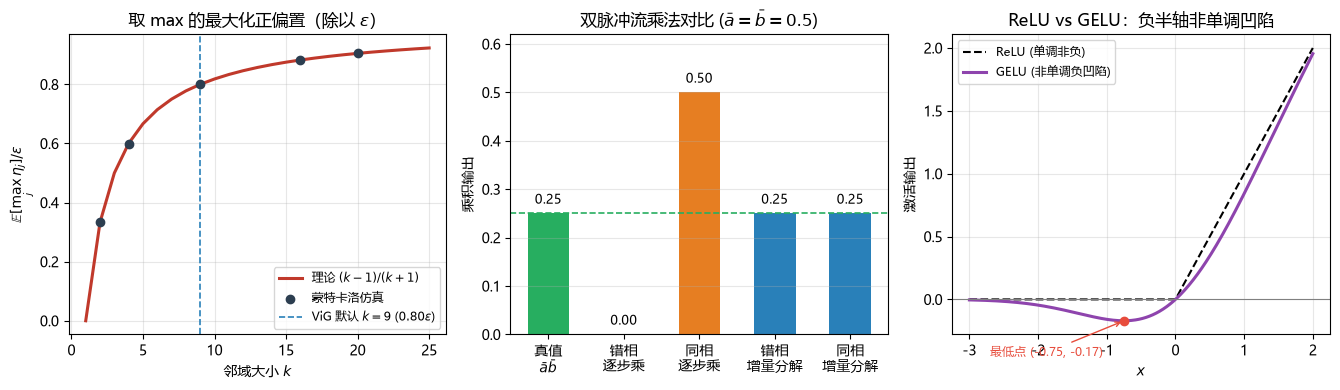

In [5]:
from math import erf, sqrt

def gelu(x):
    return 0.5 * x * (1.0 + np.vectorize(erf)(x / sqrt(2.0)))

def softmax(v):
    e = np.exp(v - np.max(v))
    return e / np.sum(e)

def layernorm(v, eps=1e-5):
    mu = np.mean(v)
    var = np.mean((v - mu) ** 2)
    return (v - mu) / np.sqrt(var + eps)

# 1) GELU: 负半轴凹陷 + 非交换性
g_neg = float(gelu(-0.75))
g_step = 0.5 * (float(gelu(1.0)) + float(gelu(-1.0)))
g_mean = float(gelu(0.0))
print("=== 例 9.5A: GELU ===")
print(f"GELU(-0.75) = {g_neg:+.4f} (非单调负凹陷！)")
print(f"两步输入 [+1, -1] (均值 0): 逐步 GELU 均值 = {g_step:+.4f} != GELU(0) = {g_mean:+.4f}")
assert g_neg < -0.16
assert abs(g_step - g_mean) > 0.34

# 2) Softmax: 跨 token 指数归一化
z_sm = np.array([[2.0, 0.0], [0.0, 0.0]])
sm_true = softmax(z_sm.mean(axis=0))
sm_step = 0.5 * (softmax(z_sm[0]) + softmax(z_sm[1]))
print("\n=== 例 9.5B: Softmax ===")
print(f"两步 logits [2,0] 与 [0,0] (均值 [1,0]):")
print(f"  真实 Softmax(均值) = {sm_true.round(4)}")
print(f"  逐步 Softmax 均值  = {sm_step.round(4)} (误差 {np.abs(sm_step - sm_true)[0]:.4f})")
assert np.max(np.abs(sm_step - sm_true)) > 0.04

# 3) LayerNorm: 逐 token 运行期均值与标准差倒数
z_ln = np.array([[2.0, 0.0, 0.0], [0.0, 2.0, 0.0]])
ln_true = layernorm(z_ln.mean(axis=0))
ln_step = 0.5 * (layernorm(z_ln[0]) + layernorm(z_ln[1]))
print("\n=== 例 9.5C: LayerNorm ===")
print(f"两步特征 [2,0,0] 与 [0,2,0] (均值 [1,1,0]):")
print(f"  真实 LN(均值) = {ln_true.round(4)}")
print(f"  逐步 LN 均值  = {ln_step.round(4)} (误差 {np.max(np.abs(ln_step - ln_true)):.4f})")
assert np.max(np.abs(ln_step - ln_true)) > 0.3

# 绘图: 3 联图
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0))

k_grid = np.arange(1, 26)
axes[0].plot(k_grid, (k_grid - 1) / (k_grid + 1), color='#c0392b', lw=2.2, label='理论 $(k-1)/(k+1)$')
axes[0].scatter(ks, [b / eps_noise for b in sim_biases], color='#2c3e50', zorder=5, label='蒙特卡洛仿真')
axes[0].axvline(9, color='#2980b9', ls='--', lw=1.2, label=r'ViG 默认 $k=9$ ($0.80\epsilon$)')
axes[0].set_title(r'取 max 的最大化正偏置（除以 $\epsilon$）')
axes[0].set_xlabel('邻域大小 $k$')
axes[0].set_ylabel(r'$\mathbb{E}[\max_j \eta_j] / \epsilon$')
axes[0].legend(fontsize=8.5)
axes[0].grid(True, alpha=0.3)

bars_x = ['真值\n' + r'$\bar{a}\bar{b}$', '错相\n逐步乘', '同相\n逐步乘', '错相\n增量分解', '同相\n增量分解']
bars_y = [0.25, 0.00, 0.50, 0.25, 0.25]
colors = ['#27ae60', '#e74c3c', '#e67e22', '#2980b9', '#2980b9']
axes[1].bar(bars_x, bars_y, color=colors, width=0.55)
axes[1].axhline(0.25, color='#27ae60', ls='--', lw=1.2)
axes[1].set_ylim(0, 0.62)
for i, v in enumerate(bars_y):
    axes[1].text(i, v + 0.02, f'{v:.2f}', ha='center', fontsize=9)
axes[1].set_title(r'双脉冲流乘法对比 ($\bar{a}=\bar{b}=0.5$)')
axes[1].set_ylabel('乘积输出')
axes[1].grid(True, axis='y', alpha=0.3)

xg = np.linspace(-3.0, 2.0, 400)
axes[2].plot(xg, relu(xg), 'k--', lw=1.5, label='ReLU (单调非负)')
axes[2].plot(xg, gelu(xg), color='#8e44ad', lw=2.2, label='GELU (非单调负凹陷)')
axes[2].scatter([-0.75], [gelu(-0.75)], color='#e74c3c', zorder=5)
axes[2].annotate('最低点 (-0.75, -0.17)', xy=(-0.75, gelu(-0.75)), xytext=(-2.7, -0.45),
                 arrowprops=dict(arrowstyle='->', color='#e74c3c'), fontsize=8.5, color='#e74c3c')
axes[2].axhline(0, color='gray', lw=0.8)
axes[2].set_title('ReLU vs GELU：负半轴非单调凹陷')
axes[2].set_xlabel('$x$')
axes[2].set_ylabel('激活输出')
axes[2].legend(fontsize=8.5)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
